# Practical 11 — Multimodal single-cell learning with SCOPE-seq2

## One cell, several biological views

SCOPE-seq2 links measurements from the same cell by an optical barcode. In this
compact teaching table, one row represents one linked cell:

$$
\boxed{\text{one cell}=\text{RNA expression}+\text{image-derived features}+
\text{a teaching phenotype label}}
$$

The central question is: **does combining transcriptomic and image-derived
information improve prediction of cellular state?**

The public GBM release contains 956 cells with both measurements. The image
modality is represented by 16 features calculated from each cell image, rather
than by raw pixels. The target in this compact file is a documented teaching
proxy based on canonical GBM marker programs; it is not a clinical annotation.

## Dataset and provenance

The source is official GEO accession **GSE151137**, sample **GSM4567140**
(PJ069), a human glioblastoma sample. The source package contains a cell-by-
gene count matrix and the paper's 16 linked image measurements.

The prepared teaching file contains one row per linked cell:

```text
cell_id, sample_id, tissue, cell_barcode, cell_type, n_counts, n_genes
gene__...                         300 compact RNA features
image__...                         16 image-derived features
```

## Local file layout

```text
week11/
├── Practical_11_Multimodal_SCOPE_seq2.ipynb
└── scope_seq2_subset/
    ├── scope_seq2_cell_multimodal.parquet
    └── README.md
```

# Part I — Inspect the paired multimodal table

In [28]:

from pathlib import Path
from types import SimpleNamespace
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import urllib.request
import zipfile
from torchview import draw_graph
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBClassifier = None
    XGBOOST_AVAILABLE = False

try:
    import optuna
    OPTUNA_AVAILABLE = True
except ImportError:
    optuna = None
    OPTUNA_AVAILABLE = False

try:
    from imblearn.over_sampling import RandomOverSampler, SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
    IMBLEARN_AVAILABLE = True
except ImportError:
    RandomOverSampler = None
    SMOTE = None
    ImbPipeline = None
    IMBLEARN_AVAILABLE = False

RANDOM_STATE = 181126
DATA_PATH = Path("scope_seq2_subset/scope_seq2_cell_multimodal.parquet")

In [29]:
scope = pd.read_parquet(DATA_PATH)
metadata_columns = [
    "cell_id", "sample_id", "tissue", "cell_barcode", "cell_type",
    "n_counts", "n_genes",
]
gene_columns = [column for column in scope.columns if column.startswith("gene__")]
image_columns = [column for column in scope.columns if column.startswith("image__")]

print("Shape:", scope.shape)
print("RNA columns:", len(gene_columns))
print("Image-feature columns:", len(image_columns))
display(scope.head())

Shape: (956, 323)
RNA columns: 300
Image-feature columns: 16


,cell_id,sample_id,tissue,cell_barcode,cell_type,n_counts,n_genes,image__area,image__perim.,image__width,...,gene__RPS15AP1,gene__METRN,gene__MORF4L1,gene__SEPT7,gene__OST4,gene__IGFBP5,gene__RPL23A,gene__RPL7A,gene__COX6C,gene__SEPW1
0,scope2_PJ069_0_0_54,PJ069,human_glioblastoma,0_0_54,astrocyte,3040,1862,-0.309259,-0.334776,-0.463003,...,0.000000,2.025374,1.456164,1.456164,2.385861,0.000000,1.456164,2.025374,0.000000,1.456164
1,scope2_PJ069_0_0_55,PJ069,human_glioblastoma,0_0_55,mesenchymal,2646,1533,1.907677,1.548103,1.485841,...,2.512673,0.000000,1.564292,0.000000,2.512673,1.564292,1.564292,1.564292,2.779884,0.000000
2,scope2_PJ069_0_0_79,PJ069,human_glioblastoma,0_0_79,mesenchymal,1628,1072,-0.349203,-0.316274,-0.219398,...,0.000000,0.000000,0.000000,2.966691,0.000000,0.000000,2.586637,0.000000,2.966691,2.586637
3,scope2_PJ069_0_10_59,PJ069,human_glioblastoma,0_10_59,mesenchymal,1965,1181,1.807815,2.246492,0.267813,...,1.806493,2.413958,0.000000,1.806493,1.806493,0.000000,0.000000,2.413958,1.806493,0.000000
4,scope2_PJ069_0_10_6,PJ069,human_glioblastoma,0_10_6,astrocyte,2328,1525,-0.768624,-0.665468,-0.463003,...,1.666864,1.666864,2.260832,0.000000,1.666864,0.000000,2.260832,3.112522,1.666864,1.666864


### What is the experimental unit?

The experimental unit is one linked cell, not one gene and not one image
feature. Every modality must be joined using the same barcode. A common
multimodal error is to shuffle or aggregate modalities independently, silently
destroying the pairing.

In [30]:
checks = {
    "one row per cell": scope["cell_id"].is_unique,
    "barcode unique": scope["cell_barcode"].is_unique,
    "no missing target": scope["cell_type"].notna().all(),
    "RNA values finite": np.isfinite(scope[gene_columns].to_numpy()).all(),
    "image values finite": np.isfinite(scope[image_columns].to_numpy()).all(),
}
display(pd.Series(checks, name="passed").to_frame())
display(scope["cell_type"].value_counts().rename("cells").to_frame())

,passed
one row per cell,True
barcode unique,True
no missing target,True
RNA values finite,True
image values finite,True


,cells
cell_type,
astrocyte,417
mesenchymal,240
myeloid,83
cycling,69
opc_npc,65
endothelial,46
pericyte,36


# Part II — EDA for the expression modality

The exported RNA columns are compact log-normalized expression values. The
metadata columns `n_counts` and `n_genes` retain quality-control summaries from
the original count matrix. We inspect them before modeling because low library
size, extreme outliers, and class imbalance can change apparent performance.

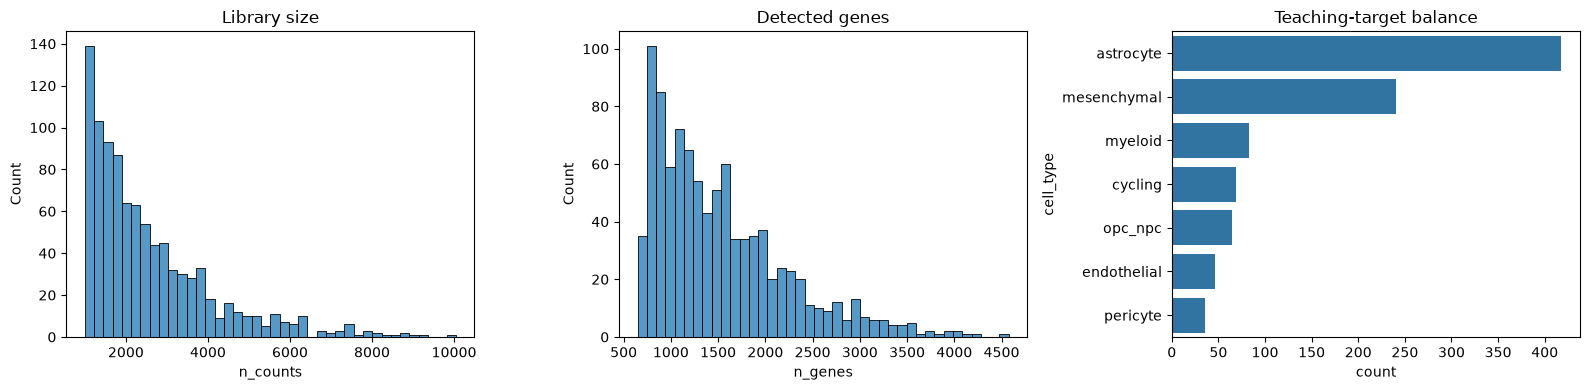

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(scope["n_counts"], bins=40, ax=axes[0])
axes[0].set_title("Library size")
sns.histplot(scope["n_genes"], bins=40, ax=axes[1])
axes[1].set_title("Detected genes")
sns.countplot(
    data=scope, y="cell_type", order=scope["cell_type"].value_counts().index, ax=axes[2]
)
axes[2].set_title("Teaching-target balance")
plt.tight_layout()

In [32]:
display(pd.DataFrame({
    "missing_fraction": scope[gene_columns].isna().mean().head(10),
    "zero_fraction": (scope[gene_columns] == 0).mean().sort_values(ascending=False).head(10),}))


,missing_fraction,zero_fraction
gene__AGT,NaN,0.610879
gene__APOE,0.0,NaN
gene__BCYRN1,0.0,NaN
gene__CD74,NaN,0.680962
gene__CLU,0.0,NaN
gene__CYR61,NaN,0.592050
gene__DUSP1,NaN,0.599372
gene__EGR1,0.0,NaN
gene__FN1,NaN,0.732218
gene__GAP43,0.0,NaN


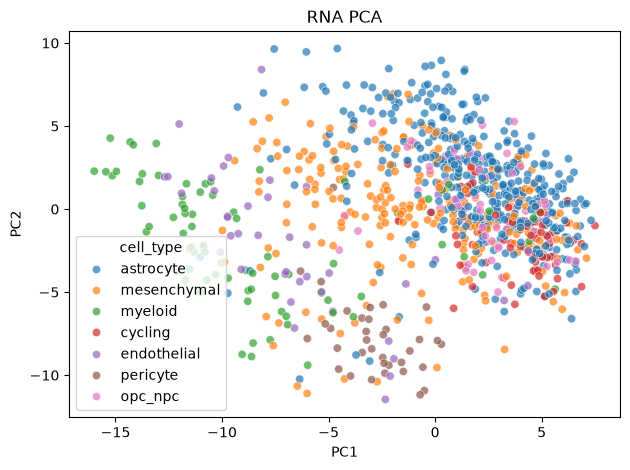

In [6]:

rna_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(
    StandardScaler().fit_transform(scope[gene_columns])
)
rna_plot = pd.DataFrame(rna_pca, columns=["PC1", "PC2"])
rna_plot["cell_type"] = scope["cell_type"].to_numpy()
sns.scatterplot(data=rna_plot, x="PC1", y="PC2", hue="cell_type", alpha=0.7)
plt.title("RNA PCA")
plt.tight_layout()

# Part III — EDA for the image-derived modality

The paper reports 16 measurements from each linked cell image. They describe
area, perimeter, width, height, major/minor axis, circularity, roundness,
solidity, Feret diameters, and intensity summaries. These are numerical image
features, so this practical treats them as a compact tabular representation
rather than training a CNN.

,count,mean,std,min,25%,50%,75%,max
image__area,956.0,4.184106e-12,1.000523,-1.497616,-0.641300,-0.249341,0.369803,6.581215
image__perim.,956.0,-1.046025e-11,1.000523,-1.590004,-0.639351,-0.271653,0.374425,6.004560
image__width,956.0,7.531382e-11,1.000523,-1.681031,-0.706609,-0.219398,0.267813,8.063190
image__height,956.0,-1.046026e-11,1.000523,-1.891316,-0.726455,-0.260510,0.205435,5.563798
image__major,956.0,-9.414221e-12,1.000523,-1.440151,-0.635808,-0.288426,0.271559,6.498233
image__minor,956.0,4.184101e-12,1.000523,-2.339777,-0.651573,-0.126218,0.457318,5.317817
image__circ.,956.0,-1.046025e-11,1.000523,-6.578886,-0.091923,0.278760,0.507128,1.112799
image__round,956.0,-8.368207e-12,1.000523,-4.362005,-0.180191,0.383315,0.628490,0.968572
image__solidity,956.0,1.987448e-11,1.000523,-10.151294,-0.210696,0.162660,0.489346,1.376066
image__feret,956.0,1.255230e-11,1.000523,-1.398041,-0.623737,-0.292752,0.269496,6.155442


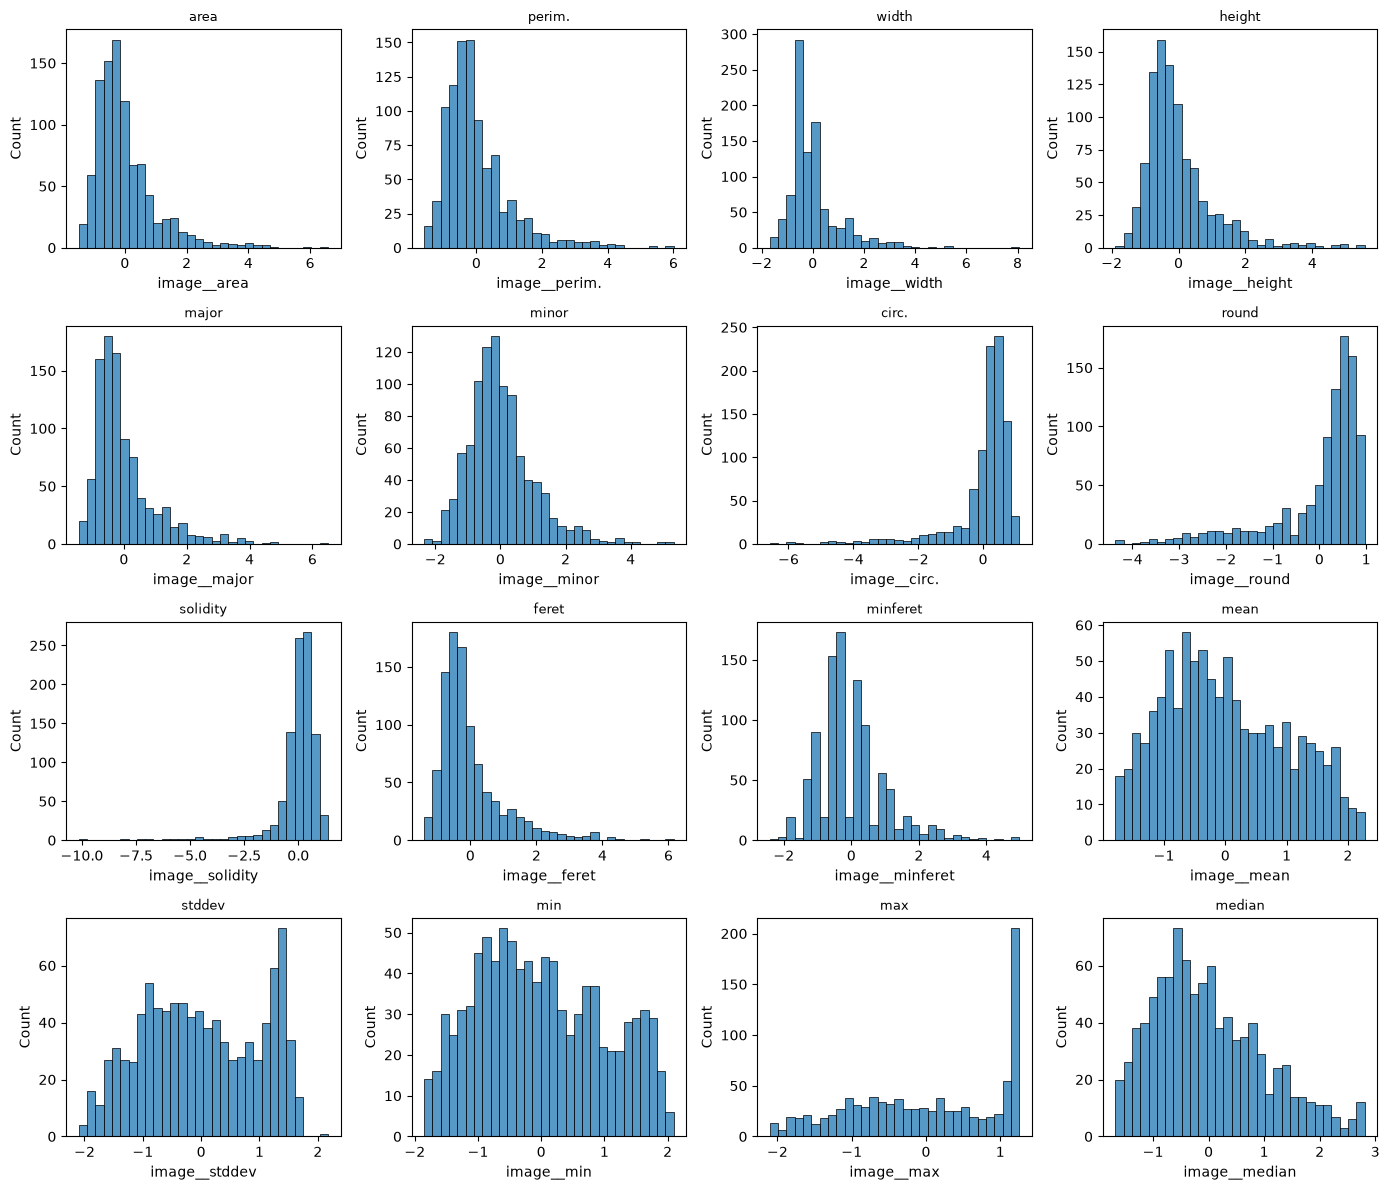

In [7]:
display(scope[image_columns].describe().T)
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for axis, column in zip(axes.flat, image_columns):
    sns.histplot(scope[column], bins=30, ax=axis)
    axis.set_title(column.removeprefix("image__"), fontsize=9)
plt.tight_layout()

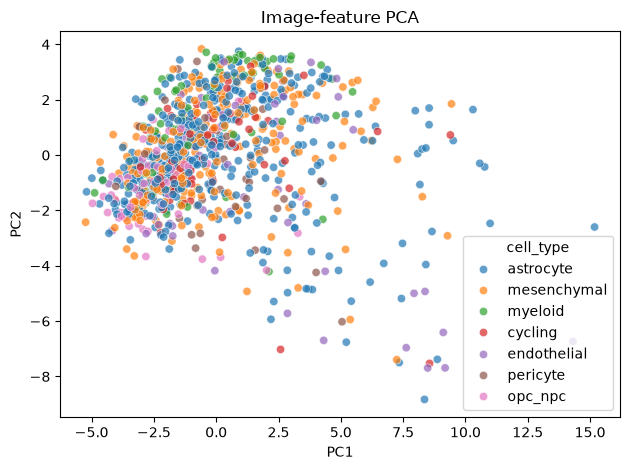

In [8]:
image_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(
    StandardScaler().fit_transform(scope[image_columns])
)
image_plot = pd.DataFrame(image_pca, columns=["PC1", "PC2"])
image_plot["cell_type"] = scope["cell_type"].to_numpy()
sns.scatterplot(data=image_plot, x="PC1", y="PC2", hue="cell_type", alpha=0.7)
plt.title("Image-feature PCA")
plt.tight_layout()

# Part IV — Split data and define reusable metrics

This release contains one tissue sample and no donor/site split. We therefore
use a stratified random split for this classroom demonstration and state the
limitation explicitly. With multiple donors or slides, the correct split would
hold out whole biological groups:

$$
\mathcal{G}_{\mathrm{train}}\cap\mathcal{G}_{\mathrm{test}}=\varnothing.
$$

The test set is not used to choose features, transformations, or hyperparameters.

In [33]:
train_df, test_df = train_test_split(
    scope, test_size=0.20, stratify=scope["cell_type"], random_state=RANDOM_STATE)

train_df, val_df = train_test_split(train_df, test_size=0.20, stratify=train_df["cell_type"], random_state=RANDOM_STATE)

label_encoder = LabelEncoder().fit(scope["cell_type"])
y_train = label_encoder.transform(train_df["cell_type"])
y_val = label_encoder.transform(val_df["cell_type"])
y_test = label_encoder.transform(test_df["cell_type"])

def report_model(name, model, X_fit, y_fit, X_eval, y_eval):
    model.fit(X_fit, y_fit)
    prediction = model.predict(X_eval)
    return {
        "model": name,
        "macro_f1": f1_score(y_eval, prediction, average="macro"),
        "balanced_accuracy": balanced_accuracy_score(y_eval, prediction),
    }

results = []

In [34]:
train_df

,cell_id,sample_id,tissue,cell_barcode,cell_type,n_counts,n_genes,image__area,image__perim.,image__width,...,gene__RPS15AP1,gene__METRN,gene__MORF4L1,gene__SEPT7,gene__OST4,gene__IGFBP5,gene__RPL23A,gene__RPL7A,gene__COX6C,gene__SEPW1
904,scope2_PJ069_9_57_91,PJ069,human_glioblastoma,9_57_91,astrocyte,2869,1871,-0.079576,-0.074746,-0.219398,...,2.075819,2.075819,1.500858,2.438566,2.075819,0.000000,0.000000,1.500858,2.075819,0.000000
523,scope2_PJ069_5_47_54,PJ069,human_glioblastoma,5_47_54,astrocyte,2803,1732,-0.059604,-0.119366,-0.219398,...,2.096202,0.000000,0.000000,0.000000,1.518989,0.000000,2.096202,1.518989,2.935878,0.000000
928,scope2_PJ069_9_76_12,PJ069,human_glioblastoma,9_76_12,astrocyte,1749,1173,-0.249341,-0.163986,0.024208,...,1.904724,2.520524,0.000000,0.000000,2.520524,3.172631,3.960012,2.520524,0.000000,1.904724
915,scope2_PJ069_9_68_15,PJ069,human_glioblastoma,9_68_15,mesenchymal,1128,844,-0.768624,-0.747018,-0.706609,...,0.000000,0.000000,2.289018,0.000000,0.000000,0.000000,2.930153,0.000000,2.289018,0.000000
249,scope2_PJ069_2_18_12,PJ069,human_glioblastoma,2_18_12,cycling,1468,916,0.509609,0.355998,0.267813,...,0.000000,0.000000,2.055660,0.000000,2.682663,0.000000,3.341021,2.682663,2.682663,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311,scope2_PJ069_2_68_1,PJ069,human_glioblastoma,2_68_1,mesenchymal,1814,1168,-0.788596,-0.791638,-0.706609,...,1.873751,0.000000,0.000000,0.000000,0.000000,0.000000,2.487018,3.352126,2.487018,0.000000
460,scope2_PJ069_4_37_64,PJ069,human_glioblastoma,4_37_64,astrocyte,1366,895,-1.138113,-1.266926,-1.193820,...,2.749914,0.000000,2.118740,0.000000,0.000000,0.000000,2.118740,2.118740,0.000000,0.000000
383,scope2_PJ069_3_35_42,PJ069,human_glioblastoma,3_35_42,mesenchymal,1128,803,-0.678748,-0.290156,-1.193820,...,2.289018,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.930153,2.930153,0.000000
414,scope2_PJ069_3_57_16,PJ069,human_glioblastoma,3_57_16,mesenchymal,2021,1252,-0.429093,-0.487064,-0.463003,...,0.000000,1.783063,2.388404,1.783063,0.000000,0.000000,3.248055,0.000000,0.000000,0.000000


In [35]:
val_df

,cell_id,sample_id,tissue,cell_barcode,cell_type,n_counts,n_genes,image__area,image__perim.,image__width,...,gene__RPS15AP1,gene__METRN,gene__MORF4L1,gene__SEPT7,gene__OST4,gene__IGFBP5,gene__RPL23A,gene__RPL7A,gene__COX6C,gene__SEPW1
917,scope2_PJ069_9_68_6,PJ069,human_glioblastoma,9_68_6,astrocyte,5152,2790,0.269941,0.274372,0.024208,...,0.000000,2.170650,1.078748,1.078748,0.000000,0.000000,2.805053,2.370708,2.537338,1.920297
270,scope2_PJ069_2_37_38,PJ069,human_glioblastoma,2_37_38,astrocyte,1678,1141,-0.439079,-0.360894,-0.463003,...,0.000000,1.940104,2.558695,0.000000,2.938020,3.427430,2.558695,0.000000,0.000000,0.000000
885,scope2_PJ069_9_38_48,PJ069,human_glioblastoma,9_38_48,mesenchymal,2339,1606,-0.628817,-0.639351,-0.463003,...,0.000000,0.000000,1.663041,0.000000,0.000000,0.000000,2.626550,1.663041,2.256611,2.256611
90,scope2_PJ069_0_82_24,PJ069,human_glioblastoma,0_82_24,astrocyte,1846,1146,-0.229369,-0.208606,0.024208,...,2.470997,1.858969,0.000000,0.000000,2.470997,0.000000,2.470997,2.470997,1.858969,1.858969
755,scope2_PJ069_8_10_35,PJ069,human_glioblastoma,8_10_35,mesenchymal,2861,1562,-0.289286,-0.271653,-0.463003,...,0.000000,0.000000,1.503028,1.503028,2.078261,4.557791,1.503028,0.000000,0.000000,1.503028
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
744,scope2_PJ069_7_82_65,PJ069,human_glioblastoma,7_82_65,opc_npc,1221,925,-0.878472,-0.899305,-0.950214,...,2.218117,0.000000,0.000000,0.000000,0.000000,0.000000,3.241421,3.241421,2.218117,0.000000
954,scope2_PJ069_9_92_75,PJ069,human_glioblastoma,9_92_75,opc_npc,1941,1259,-0.718693,-0.747018,-0.706609,...,2.800687,2.800687,1.816775,0.000000,2.425154,0.000000,3.286905,2.425154,2.425154,1.816775
589,scope2_PJ069_6_25_73,PJ069,human_glioblastoma,6_25_73,mesenchymal,1093,783,-0.778610,-0.791638,-0.463003,...,2.960015,0.000000,0.000000,0.000000,0.000000,0.000000,2.317388,2.960015,3.626912,0.000000
20,scope2_PJ069_0_28_53,PJ069,human_glioblastoma,0_28_53,endothelial,2124,1446,0.929029,0.723620,0.998630,...,0.000000,2.987317,2.716302,0.000000,0.000000,1.741886,3.200324,1.741886,2.343362,1.741886


# Part V — Class balance and resampling

The target is imbalanced: some marker-program groups contain many more cells
than others. Accuracy can therefore look acceptable while minority classes are
poorly recognized. We use macro-F1 and balanced accuracy so every class
contributes to the evaluation.

There are three common responses:

1. class_weight="balanced" changes the loss contribution of each class;
2. random oversampling duplicates minority training cells;
3. SMOTE creates synthetic numeric points between minority neighbors.

Resampling must be performed inside a training pipeline. It must never see
validation or test cells, otherwise synthetic examples can leak information
from held-out data. The notebook always runs a small NumPy implementation of
random oversampling; if imbalanced-learn is installed, it additionally runs a
proper SMOTE pipeline.

,training_cells
cell_type,
astrocyte,266
mesenchymal,153
myeloid,53
cycling,44
opc_npc,42
endothelial,30
pericyte,23


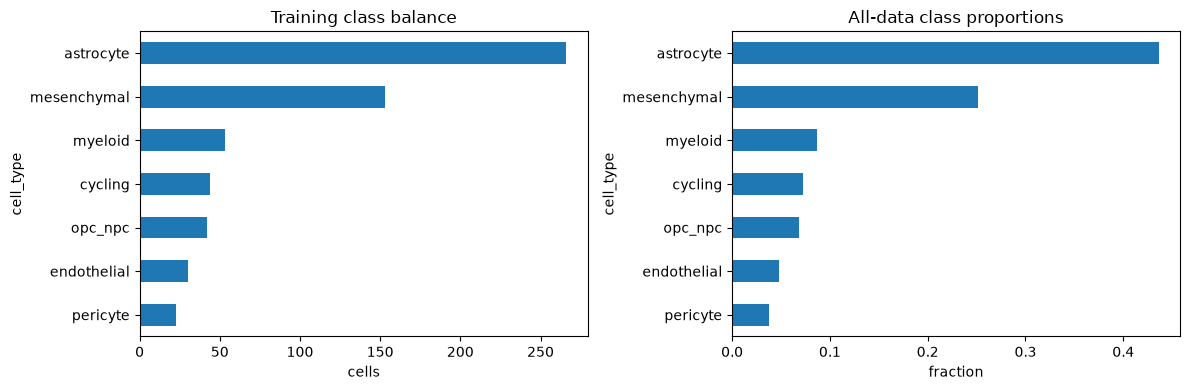

In [36]:
train_balance = train_df["cell_type"].value_counts().rename("training_cells")
display(train_balance.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_balance.sort_values().plot.barh(ax=axes[0], title="Training class balance")
axes[0].set_xlabel("cells")
scope["cell_type"].value_counts(normalize=True).sort_values().plot.barh(
    ax=axes[1], title="All-data class proportions"
)
axes[1].set_xlabel("fraction")
plt.tight_layout()

In [37]:
def random_oversample_training(frame, labels):
    rng = np.random.default_rng(RANDOM_STATE)
    labels = np.asarray(labels)
    class_indices = [np.flatnonzero(labels == class_id) for class_id in np.unique(labels)]
    target_size = max(len(indices) for indices in class_indices)
    selected = np.concatenate([
        rng.choice(indices, size=target_size, replace=True)
        for indices in class_indices
    ])
    rng.shuffle(selected)
    return frame.iloc[selected].reset_index(drop=True), labels[selected]

balance_results = []
rna_balanced_X, rna_balanced_y = random_oversample_training(
    train_df[gene_columns], y_train
)
manual_rna_over = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=min(50, len(gene_columns)), random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1500)),
])
balance_results.append(report_model(
    "RNA + random oversampling + logistic regression", manual_rna_over,
    rna_balanced_X, rna_balanced_y, test_df[gene_columns], y_test,
))

if IMBLEARN_AVAILABLE:
    rna_smote = ImbPipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=min(50, len(gene_columns)), random_state=RANDOM_STATE)),
        ("smote", SMOTE(k_neighbors=3, random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=1500)),
    ])
    balance_results.append(report_model(
        "RNA + SMOTE + logistic regression", rna_smote,
        train_df[gene_columns], y_train, test_df[gene_columns], y_test,
    ))

    image_random_over = ImbPipeline([
        ("scale", StandardScaler()),
        ("oversample", RandomOverSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(max_iter=1500)),
    ])
    balance_results.append(report_model(
        "image + random oversampling + logistic regression", image_random_over,
        train_df[image_columns], y_train, test_df[image_columns], y_test,
    ))
else:
    print("Optional imbalanced-learn is not installed; manual random oversampling was used.")

results.extend(balance_results)
display(pd.DataFrame(balance_results))

,model,macro_f1,balanced_accuracy
0,RNA + random oversampling + logistic regression,0.600337,0.629229
1,RNA + SMOTE + logistic regression,0.663605,0.663273
2,image + random oversampling + logistic regression,0.203910,0.331041


# Part VI — Mutual information for both modalities

Mutual information measures statistical dependence:

$$
I(X;Y)=\sum_{x,y}p(x,y)\log\left(\frac{p(x,y)}{p(x)p(y)}\right).
$$

It is zero when variables are independent and increases when a feature contains
information about the label. We estimate it on training cells only; using the
held-out cells for feature screening would leak information.

In [12]:
def mutual_information_table(frame, columns, modality):
    values = mutual_info_classif(
        frame[columns], label_encoder.transform(frame["cell_type"]), random_state=RANDOM_STATE
    )
    return (
        pd.DataFrame({"feature": columns, "mutual_information": values})
        .sort_values("mutual_information", ascending=False)
        .assign(modality=modality)
    )

mi_rna = mutual_information_table(train_df, gene_columns, "RNA")
mi_image = mutual_information_table(train_df, image_columns, "image")
display(pd.concat([mi_rna.head(10), mi_image.head(10)]))

,feature,mutual_information,modality
88,gene__MT3,0.254165,RNA
27,gene__C1orf61,0.247595,RNA
5,gene__IGFBP7,0.224614,RNA
6,gene__CLU,0.223471,RNA
19,gene__CD74,0.194857,RNA
59,gene__SPARC,0.185393,RNA
69,gene__PSAP,0.177322,RNA
38,gene__TUBA1B,0.170136,RNA
0,gene__SPP1,0.169013,RNA
14,gene__IFITM3,0.162684,RNA


# Part VII — RNA-only models

The RNA baseline keeps preprocessing in a pipeline. Standardization and PCA are
fitted on training cells only, then reused unchanged for validation and test:

$$
X_{\mathrm{RNA}}\rightarrow\mathrm{standardize}\rightarrow\mathrm{PCA}
\rightarrow\mathrm{logistic\ regression}.
$$

In [38]:
rna_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=min(50, len(gene_columns)), random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1500, class_weight="balanced")),
])
results.append(report_model(
    "RNA + PCA + logistic regression", rna_pipeline,
    train_df[gene_columns], y_train, test_df[gene_columns], y_test,
))
display(pd.DataFrame(results))

,model,macro_f1,balanced_accuracy
0,RNA + random oversampling + logistic regression,0.600337,0.629229
1,RNA + SMOTE + logistic regression,0.663605,0.663273
2,image + random oversampling + logistic regression,0.203910,0.331041
3,RNA + PCA + logistic regression,0.669915,0.684041


In [41]:
display(pd.DataFrame(results))

,model,macro_f1,balanced_accuracy
0,RNA + random oversampling + logistic regression,0.600337,0.629229
1,RNA + SMOTE + logistic regression,0.663605,0.663273
2,image + random oversampling + logistic regression,0.203910,0.331041
3,RNA + PCA + logistic regression,0.669915,0.684041
4,image features + logistic regression,0.225047,0.395188
5,image SVM (linear),0.222744,0.359657
6,image SVM (rbf),0.250561,0.406107
7,image SVM (poly),0.176572,0.280988


# Part VIII — Image-feature models

In [39]:
image_logistic = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1500, class_weight="balanced")),
])
results.append(report_model(
    "image features + logistic regression", image_logistic,
    train_df[image_columns], y_train, test_df[image_columns], y_test,
))

kernel_results = []
for kernel in ["linear", "rbf", "poly"]:
    model = Pipeline([
        ("scale", StandardScaler()),
        ("svm", SVC(kernel=kernel, C=1.0, class_weight="balanced")),
    ])
    kernel_results.append(report_model(
        f"image SVM ({kernel})", model,
        train_df[image_columns], y_train, test_df[image_columns], y_test,
    ))
results.extend(kernel_results)
display(pd.DataFrame(kernel_results))

,model,macro_f1,balanced_accuracy
0,image SVM (linear),0.222744,0.359657
1,image SVM (rbf),0.250561,0.406107
2,image SVM (poly),0.176572,0.280988


# Part IX — Tuned XGBoost baselines

Tree ensembles also need tuning. The parameters max_depth, learning_rate, and
n_estimators control model capacity and the bias--variance trade-off. We use
Optuna's TPE sampler to explore a wider search space while keeping the number
of trials bounded for classroom use. Each trial is scored on an inner split of
the training cells; the outer test set remains untouched.

In [42]:
def tuned_xgb(X, y, n_trials=50):
    if not XGBOOST_AVAILABLE or not OPTUNA_AVAILABLE:
        return None

    X_inner, X_valid, y_inner, y_valid = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
    )
    fixed_params = {
        "objective": "multi:softprob",
        "num_class": len(label_encoder.classes_),
        "eval_metric": "mlogloss",
        "tree_method": "hist",
        "random_state": RANDOM_STATE,
        "n_jobs": 2,
        "verbosity": 0,
    }

    def objective(trial):
        trial_params = {
            "n_estimators": trial.suggest_int("n_estimators", 10, 800, step=50),
            "max_depth": trial.suggest_int("max_depth", 2, 12),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.35, log=True),
            "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
            "subsample": trial.suggest_float("subsample", 0.25, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.20, 1.0),
            "gamma": trial.suggest_float("gamma", 0.0, 5.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 30.0, log=True),
        }
        model = XGBClassifier(**fixed_params, **trial_params)
        model.fit(X_inner, y_inner)
        prediction = model.predict(X_valid)
        return f1_score(y_valid, prediction, average="macro")

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    )
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)

    best_model = XGBClassifier(**fixed_params, **study.best_params)
    best_model.fit(X, y)
    return SimpleNamespace(best_estimator_=best_model, study=study)

xgb_searches = {}
for name, columns in [("RNA XGBoost", gene_columns), ("image XGBoost", image_columns)]:
    search = tuned_xgb(train_df[columns], y_train)
    if search is not None:
        xgb_searches[name] = search
        results.append(report_model(
            name, search.best_estimator_, train_df[columns], y_train,
            test_df[columns], y_test,
        ))
display(pd.DataFrame(results))

C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\optuna\distributions.py:684: UserWarning: The distribution is specified by [10, 800] and step=50, but the range is not divisible by `step`. It will be replaced with [10, 760].
  optuna_warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\optuna\distributions.py:684: UserWarning: The distribution is specified by [10, 800] and step=50, but the range is not divisible by `step`. It will be replaced with [10, 760].
  optuna_warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\optuna\distributions.py:684: UserWarning: The distribution is specified by [10, 800] and step=50, but the range is not divisible by `step`. It will be replaced with [10, 760].
  optuna_warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\optuna\distributions.py:684: UserWarning: The distribution is specified by [10, 800] and step=50, but the range is not divisible by `step`.

,model,macro_f1,balanced_accuracy
0,RNA + random oversampling + logistic regression,0.600337,0.629229
1,RNA + SMOTE + logistic regression,0.663605,0.663273
2,image + random oversampling + logistic regression,0.203910,0.331041
3,RNA + PCA + logistic regression,0.669915,0.684041
4,image features + logistic regression,0.225047,0.395188
5,image SVM (linear),0.222744,0.359657
6,image SVM (rbf),0.250561,0.406107
7,image SVM (poly),0.176572,0.280988
8,RNA XGBoost,0.660531,0.623327
9,image XGBoost,0.252712,0.230000


# Part X — Early fusion

Early fusion concatenates the two representations before fitting one model:

$$
z_{\mathrm{early}}=[z_{\mathrm{RNA}},z_{\mathrm{image}}].
$$

This lets the model learn interactions between modalities, but makes the input
wider and more sensitive to scaling and missing modality values.

In [43]:
early_columns = gene_columns + image_columns
early_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced")),
])
results.append(report_model(
    "early fusion + logistic regression", early_model,
    train_df[early_columns], y_train, test_df[early_columns], y_test,
))

early_xgb = tuned_xgb(train_df[early_columns], y_train)
if early_xgb is not None:
    results.append(report_model(
        "early fusion + tuned XGBoost", early_xgb.best_estimator_,
        train_df[early_columns], y_train, test_df[early_columns], y_test,
    ))
display(pd.DataFrame(results).tail(3))

C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\optuna\distributions.py:684: UserWarning: The distribution is specified by [10, 800] and step=50, but the range is not divisible by `step`. It will be replaced with [10, 760].
  optuna_warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\optuna\distributions.py:684: UserWarning: The distribution is specified by [10, 800] and step=50, but the range is not divisible by `step`. It will be replaced with [10, 760].
  optuna_warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\optuna\distributions.py:684: UserWarning: The distribution is specified by [10, 800] and step=50, but the range is not divisible by `step`. It will be replaced with [10, 760].
  optuna_warn(
C:\Users\user\Desktop\kse\practicals\kse-github\.venv\Lib\site-packages\optuna\distributions.py:684: UserWarning: The distribution is specified by [10, 800] and step=50, but the range is not divisible by `step`.

,model,macro_f1,balanced_accuracy
9,image XGBoost,0.252712,0.230000
10,early fusion + logistic regression,0.623131,0.596292
11,early fusion + tuned XGBoost,0.674470,0.627873


# Part XI — Late fusion

Late fusion trains separate predictors and combines their probabilities:

$$
p_{\mathrm{final}}=\alpha p_{\mathrm{RNA}}+(1-\alpha)p_{\mathrm{image}},
\qquad 0\leq\alpha\leq1.
$$

The modalities can use different models. The weight is selected on the
validation set, not on the test set.

In [44]:
rna_model = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=min(50, len(gene_columns)), random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1500, class_weight="balanced")),
]).fit(train_df[gene_columns], y_train)
image_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=1500, class_weight="balanced")),
]).fit(train_df[image_columns], y_train)

rna_val_proba = rna_model.predict_proba(val_df[gene_columns])
image_val_proba = image_model.predict_proba(val_df[image_columns])
weights = np.linspace(0, 1, 11)
validation_scores = [
    f1_score(y_val, np.argmax(alpha * rna_val_proba + (1 - alpha) * image_val_proba, axis=1), average="macro")
    for alpha in weights
]
alpha = float(weights[int(np.argmax(validation_scores))])

late_proba = alpha * rna_model.predict_proba(test_df[gene_columns]) + (1 - alpha) * image_model.predict_proba(test_df[image_columns])
late_prediction = np.argmax(late_proba, axis=1)
results.append({
    "model": f"late fusion logistic (alpha={alpha:.1f})",
    "macro_f1": f1_score(y_test, late_prediction, average="macro"),
    "balanced_accuracy": balanced_accuracy_score(y_test, late_prediction),
})

if {"RNA XGBoost", "image XGBoost"}.issubset(xgb_searches):
    rna_xgb = xgb_searches["RNA XGBoost"].best_estimator_
    image_xgb = xgb_searches["image XGBoost"].best_estimator_
    rna_xgb_val = rna_xgb.predict_proba(val_df[gene_columns])
    image_xgb_val = image_xgb.predict_proba(val_df[image_columns])
    xgb_scores = [
        f1_score(y_val, np.argmax(weight * rna_xgb_val + (1 - weight) * image_xgb_val, axis=1), average="macro")
        for weight in weights
    ]
    xgb_alpha = float(weights[int(np.argmax(xgb_scores))])
    xgb_proba = xgb_alpha * rna_xgb.predict_proba(test_df[gene_columns]) + (1 - xgb_alpha) * image_xgb.predict_proba(test_df[image_columns])
    xgb_prediction = np.argmax(xgb_proba, axis=1)
    results.append({
        "model": f"late fusion XGBoost (alpha={xgb_alpha:.1f})",
        "macro_f1": f1_score(y_test, xgb_prediction, average="macro"),
        "balanced_accuracy": balanced_accuracy_score(y_test, xgb_prediction),
    })
display(pd.DataFrame(results).tail(2))

,model,macro_f1,balanced_accuracy
12,late fusion logistic (alpha=0.5),0.675759,0.708961
13,late fusion XGBoost (alpha=1.0),0.660531,0.623327


# Part XII — Joint latent fusion

Joint latent fusion learns one small encoder per modality and concatenates the
latent vectors before the prediction head:

$$
z_{\mathrm{RNA}}=g_{\mathrm{RNA}}(x_{\mathrm{RNA}}),\qquad
z_{\mathrm{image}}=g_{\mathrm{image}}(x_{\mathrm{image}}),
$$

$$
\hat{y}=h([z_{\mathrm{RNA}},z_{\mathrm{image}}]).
$$

This differs from early fusion because each modality first gets a task-specific
representation. For one input row, the computation is:

    RNA:   300 features -> Linear(300, 64) -> ReLU -> Linear(64, 16) -> z_RNA
    image:  16 features -> Linear(16, 32)  -> ReLU -> Linear(32, 16) -> z_image

                        [z_RNA, z_image] -> ReLU -> Linear(32, 7) -> logits

The two 16-dimensional vectors are latent embeddings: compact learned
representations of the original modalities. We will visualize them after
training with PCA. This is an inspection tool, not another model-selection
step.

In [45]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

class JointFusionMLP(nn.Module):
    def __init__(self, n_rna, n_image, n_classes):
        super().__init__()
        self.rna_encoder = nn.Sequential(nn.Linear(n_rna, 64), nn.ReLU(), nn.Linear(64, 16))
        self.image_encoder = nn.Sequential(nn.Linear(n_image, 32), nn.ReLU(), nn.Linear(32, 16))
        self.head = nn.Sequential(nn.ReLU(), nn.Linear(32, n_classes))

    def encode(self, rna, image):
        z_rna = self.rna_encoder(rna)
        z_image = self.image_encoder(image)
        return torch.cat([z_rna, z_image], dim=1)

    def forward(self, rna, image, return_latent=False):
        latent = self.encode(rna, image)
        logits = self.head(latent)
        return (logits, latent) if return_latent else logits

### Visualize the joint latent-fusion encoder

The graph makes the two encoder branches explicit. RNA and image features are
transformed separately, their latent vectors are concatenated, and the shared
head produces class logits. The diagram describes the computation graph; it
does not show learned parameter values.


(process:12996): Pango-WARNING **: 19:09:10.714: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


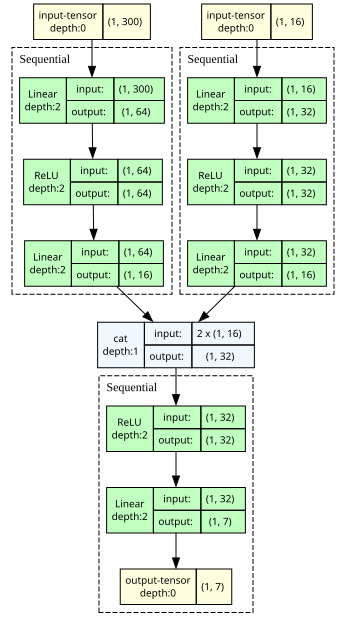

In [46]:
try:
    graph_model = JointFusionMLP(
        len(gene_columns), len(image_columns), len(label_encoder.classes_)
    ).cpu()
    fusion_graph = draw_graph(
        graph_model,
        input_data=(
            torch.zeros(1, len(gene_columns)),
            torch.zeros(1, len(image_columns)),
        ),
        expand_nested=True,
        roll=True,
        graph_name="joint_latent_fusion_encoder",
    )
    display(fusion_graph.visual_graph)
except Exception as error:
    print(
        "The model is valid, but the graph renderer is unavailable. "
        "Install the Graphviz system executable if this cell fails."
    )
    print(type(error).__name__, error)

Validation macro-F1: 0.641140350877193
Test macro-F1: 0.6516526610644258


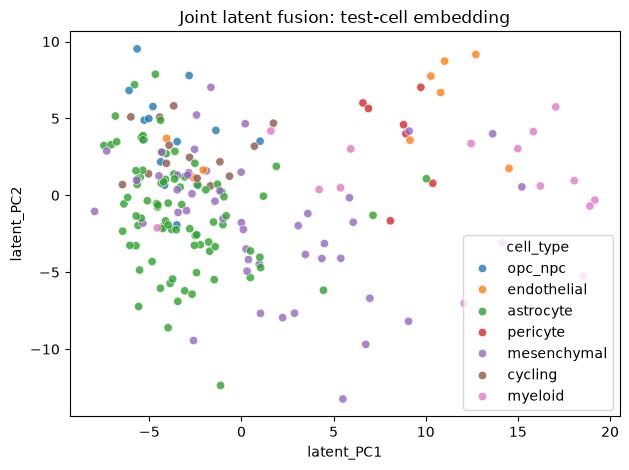

In [47]:
rna_scaler = StandardScaler().fit(train_df[gene_columns])
image_scaler = StandardScaler().fit(train_df[image_columns])
Xr_train = rna_scaler.transform(train_df[gene_columns]).astype("float32")
Xi_train = image_scaler.transform(train_df[image_columns]).astype("float32")
Xr_val = rna_scaler.transform(val_df[gene_columns]).astype("float32")
Xi_val = image_scaler.transform(val_df[image_columns]).astype("float32")
Xr_test = rna_scaler.transform(test_df[gene_columns]).astype("float32")
Xi_test = image_scaler.transform(test_df[image_columns]).astype("float32")

fusion_model = JointFusionMLP(len(gene_columns), len(image_columns), len(label_encoder.classes_)).to(DEVICE)
optimizer = torch.optim.Adam(fusion_model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()
train_loader = DataLoader(
    TensorDataset(torch.tensor(Xr_train), torch.tensor(Xi_train), torch.tensor(y_train)),
    batch_size=64, shuffle=True,
)

for epoch in range(25):
    fusion_model.train()
    for rna_batch, image_batch, target_batch in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(fusion_model(rna_batch.to(DEVICE), image_batch.to(DEVICE)), target_batch.to(DEVICE))
        loss.backward()
        optimizer.step()

fusion_model.eval()
with torch.no_grad():
    val_prediction = fusion_model(
        torch.tensor(Xr_val).to(DEVICE), torch.tensor(Xi_val).to(DEVICE)
    ).argmax(1).cpu().numpy()
print("Validation macro-F1:", f1_score(y_val, val_prediction, average="macro"))

with torch.no_grad():
    test_logits, test_latent = fusion_model(
        torch.tensor(Xr_test).to(DEVICE), torch.tensor(Xi_test).to(DEVICE),
        return_latent=True,
    )
test_prediction = test_logits.argmax(1).cpu().numpy()
results.append({
    "model": "joint latent fusion",
    "macro_f1": f1_score(y_test, test_prediction, average="macro"),
    "balanced_accuracy": balanced_accuracy_score(y_test, test_prediction),
})
print("Test macro-F1:", results[-1]["macro_f1"])

latent_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(
    test_latent.cpu().numpy()
)
latent_plot = pd.DataFrame(latent_2d, columns=["latent_PC1", "latent_PC2"])
latent_plot["cell_type"] = test_df["cell_type"].to_numpy()
sns.scatterplot(
    data=latent_plot, x="latent_PC1", y="latent_PC2",
    hue="cell_type", alpha=0.8,
)
plt.title("Joint latent fusion: test-cell embedding")
plt.tight_layout()

# Part XIII — Compare the multimodal models

,model,macro_f1,balanced_accuracy
12,late fusion logistic (alpha=0.5),0.675759,0.708961
11,early fusion + tuned XGBoost,0.674470,0.627873
3,RNA + PCA + logistic regression,0.669915,0.684041
1,RNA + SMOTE + logistic regression,0.663605,0.663273
8,RNA XGBoost,0.660531,0.623327
13,late fusion XGBoost (alpha=1.0),0.660531,0.623327
14,joint latent fusion,0.651653,0.623994
10,early fusion + logistic regression,0.623131,0.596292
0,RNA + random oversampling + logistic regression,0.600337,0.629229
9,image XGBoost,0.252712,0.230000


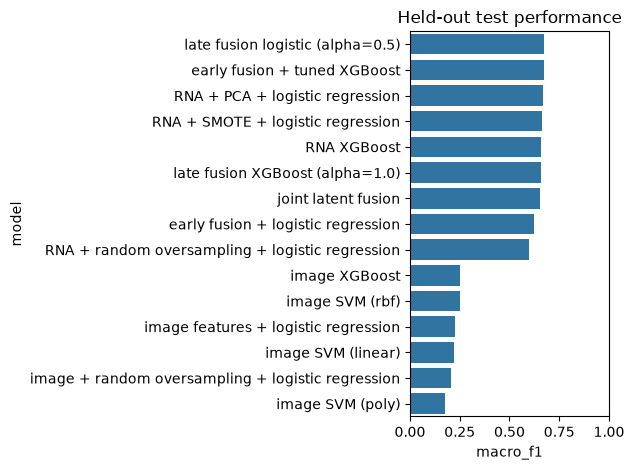

In [48]:
results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False)
display(results_df)
sns.barplot(data=results_df, x="macro_f1", y="model")
plt.xlim(0, 1)
plt.title("Held-out test performance")
plt.tight_layout()

# Homework — Multimodal fusion with UCI Human Activity Recognition

For the homework, use the **UCI Human Activity Recognition Using Smartphones**
dataset. Each observation is a 2.56-second window recorded from one person
wearing a waist-mounted smartphone. The two modalities are:

- accelerometer-derived features (`Acc` in the feature name);
- gyroscope-derived features (`Gyro` in the feature name).

The target is one of six activities. The `subject` identifier is essential:
measurements from one person must not be split between training and testing.
The goal is to compare what each modality contributes and how different fusion
strategies use that information.

## Required comparison

Build and compare these five systems:

1. accelerometer-only model;
2. gyroscope-only model;
3. early fusion: concatenate both feature blocks before modeling;
4. late fusion: train one model per modality and combine validation/test
   probabilities;
5. joint latent fusion: encode each modality separately, concatenate the two
   latent vectors, and predict from the shared representation.

Report accuracy, macro-F1, balanced accuracy, and a confusion matrix for every
system. Use the validation set to choose hyperparameters and the late-fusion
weight. Use the test set only for the final comparison.

In [ ]:

UCI_HAR_URL = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human%2Bactivity%2Brecognition%2Busing%2Bsmartphones.zip"
)
UCI_HAR_DIR = Path("uci_har_data")
UCI_HAR_ROOT = UCI_HAR_DIR / "UCI HAR Dataset"
UCI_HAR_ARCHIVE = UCI_HAR_DIR / "uci_har.zip"

if not UCI_HAR_ROOT.exists():
    UCI_HAR_DIR.mkdir(parents=True, exist_ok=True)
    if not UCI_HAR_ARCHIVE.exists():
        print("Downloading the 58 MB UCI HAR archive...")
        urllib.request.urlretrieve(UCI_HAR_URL, UCI_HAR_ARCHIVE)
    with zipfile.ZipFile(UCI_HAR_ARCHIVE) as outer_archive:
        nested_name = "UCI HAR Dataset.zip"
        outer_archive.extract(nested_name, UCI_HAR_DIR)
    with zipfile.ZipFile(UCI_HAR_DIR / nested_name) as dataset_archive:
        dataset_archive.extractall(UCI_HAR_DIR)

feature_table = pd.read_csv(
    UCI_HAR_ROOT / "features.txt",
    sep=r"\s+",
    header=None,
    names=["feature_id", "feature_name"],
    engine="python",
)

def make_unique_names(names):
    counts = {}
    unique_names = []
    for name in names:
        count = counts.get(name, 0)
        unique_names.append(name if count == 0 else f"{name}__{count}")
        counts[name] = count + 1
    return unique_names

feature_names = make_unique_names(feature_table["feature_name"].tolist())

X_train_har = pd.read_csv(
    UCI_HAR_ROOT / "train" / "X_train.txt",
    sep=r"\s+", header=None, names=feature_names, engine="python",
)
X_test_har = pd.read_csv(
    UCI_HAR_ROOT / "test" / "X_test.txt",
    sep=r"\s+", header=None, names=feature_names, engine="python",
)
y_train_codes = pd.read_csv(
    UCI_HAR_ROOT / "train" / "y_train.txt",
    header=None, names=["activity_code"],
).squeeze()
y_test_codes = pd.read_csv(
    UCI_HAR_ROOT / "test" / "y_test.txt",
    header=None, names=["activity_code"],
).squeeze()
subject_train = pd.read_csv(
    UCI_HAR_ROOT / "train" / "subject_train.txt",
    header=None, names=["subject"],
).squeeze()
subject_test = pd.read_csv(
    UCI_HAR_ROOT / "test" / "subject_test.txt",
    header=None, names=["subject"],
).squeeze()

activity_labels = pd.read_csv(
    UCI_HAR_ROOT / "activity_labels.txt",
    sep=r"\s+", header=None, names=["activity_code", "activity"],
)
activity_map = dict(
    zip(activity_labels["activity_code"], activity_labels["activity"])
)

X_har = pd.concat([X_train_har, X_test_har], ignore_index=True)
y_har = pd.concat([y_train_codes, y_test_codes], ignore_index=True).map(activity_map)
subject_har = pd.concat([subject_train, subject_test], ignore_index=True).to_numpy()

print("Feature table:", X_har.shape)
print("Target classes:", sorted(y_har.unique()))
print("Subjects:", len(np.unique(subject_har)))
display(X_har.head())
display(y_har.value_counts().rename("windows").to_frame())

Feature table: (10299, 561)
Target classes: ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']
Subjects: 30


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


,windows
activity_code,
LAYING,1944
STANDING,1906
SITTING,1777
WALKING,1722
WALKING_UPSTAIRS,1544
WALKING_DOWNSTAIRS,1406


In [50]:

accelerometer_columns = [
    column for column in X_har.columns if "Acc" in str(column)]
gyroscope_columns = [
    column for column in X_har.columns if "Gyro" in str(column)]

assert accelerometer_columns, "No accelerometer columns were detected."
assert gyroscope_columns, "No gyroscope columns were detected."

X_acc_har = X_har[accelerometer_columns].astype("float32")
X_gyro_har = X_har[gyroscope_columns].astype("float32")
X_early_har = pd.concat([X_acc_har, X_gyro_har], axis=1)

label_encoder_har = LabelEncoder().fit(y_har)
y_har_encoded = label_encoder_har.transform(y_har)

print("Accelerometer features:", X_acc_har.shape[1])
print("Gyroscope features:", X_gyro_har.shape[1])
print("Early-fusion features:", X_early_har.shape[1])

Accelerometer features: 345
Gyroscope features: 213
Early-fusion features: 558


### Leakage-safe subject split

`StratifiedGroupKFold` balances activity labels while keeping every subject in
exactly one split. 

In [ ]:
outer_splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)
train_val_relative, test_relative = next(
    outer_splitter.split(X_har, y_har_encoded, groups=subject_har))

train_val_indices = np.asarray(train_val_relative)
test_indices = np.asarray(test_relative)

inner_splitter = StratifiedGroupKFold(
    n_splits=4, shuffle=True, random_state=RANDOM_STATE
)
train_relative, val_relative = next(
    inner_splitter.split(
        X_har.iloc[train_val_indices],
        y_har_encoded[train_val_indices],
        groups=subject_har[train_val_indices],
    )
)

train_indices = train_val_indices[train_relative]
val_indices = train_val_indices[val_relative]

def subjects_in(indices):
    return set(subject_har[indices])

print("Rows:", {
    "train": len(train_indices),
    "validation": len(val_indices),
    "test": len(test_indices),
})
print("Subjects:", {
    "train": len(subjects_in(train_indices)),
    "validation": len(subjects_in(val_indices)),
    "test": len(subjects_in(test_indices)),
})
assert subjects_in(train_indices).isdisjoint(subjects_in(val_indices))
assert subjects_in(train_indices).isdisjoint(subjects_in(test_indices))
assert subjects_in(val_indices).isdisjoint(subjects_in(test_indices))

Rows: {'train': 6193, 'validation': 2144, 'test': 1962}
Subjects: {'train': 18, 'validation': 6, 'test': 6}


In [27]:
# Ready-to-use modality blocks for the five homework experiments.
har_blocks = {
    "accelerometer": X_acc_har,
    "gyroscope": X_gyro_har,
    "early_fusion": X_early_har,
}

har_splits = {
    "train": train_indices,
    "validation": val_indices,
    "test": test_indices,
}

for name, block in har_blocks.items():
    print(name, block.shape)

# TODO: build the two single-modality baselines first.
# TODO: concatenate standardized modality probabilities for late fusion.
# TODO: implement the two-branch latent-fusion model.

accelerometer (10299, 345)
gyroscope (10299, 213)
early_fusion (10299, 558)


## Homework questions

1. Do accelerometer and gyroscope achieve similar performance when modeled
   separately? Which activities are difficult for each modality?
2. Does early fusion improve macro-F1 over the best single-modality model?
3. Which validation-set probability weight gives the best late-fusion result?
4. Does joint latent fusion outperform concatenation? Inspect the learned
   latent representation with PCA or UMAP.
5. Verify that the reported test improvement is not caused by subject leakage.
6. Discuss one situation in which late fusion would be preferable to early or
   latent fusion.